# Patch-wise PCA — MVTec AD anomaly detection

**CS663 Digital Image Processing project**

This notebook implements the Claude-reviewed patch PCA design directly in the notebook (NumPy only; no sklearn PCA in the detector). It fits one shared PCA subspace to overlapping patches extracted from **normal training images only**.

Protocol:
- Training: fit the patch mean and principal subspace using normal train images only.
- Validation: normal-only split used to calibrate an image threshold at 5% false-positive rate.
- Test: official MVTec test split used only for final metrics.
- Baseline: 32×32 patches, stride 16, 95% retained patch variance, 10,000 deterministic sampled training patches.
- Anomaly map: fold per-pixel squared reconstruction residuals from overlapping patches and average their overlaps.


## 1. Setup: Drive, repository and dataset

In [17]:
from google.colab import drive
from pathlib import Path
import os, sys, subprocess

drive.mount('/content/drive')
REPO = Path('/content/CS-663')
if not REPO.exists():
    subprocess.run(['git', 'clone', 'https://github.com/pranitas-cloud/CS-663.git', str(REPO)], check=True)
else:
    subprocess.run(['git', '-C', str(REPO), 'pull', '--ff-only', 'origin', 'main'], check=True)
os.chdir(REPO)
if str(REPO.resolve()) not in sys.path:
    sys.path.insert(0, str(REPO.resolve()))

from src.data.pipelines import load_config, build_dataset, stack_images

cfg = load_config('configs/default.yaml')
cfg['data']['root'] = '/content/drive/MyDrive/CS663_Shared/datasets/mvtec_anomaly_detection'
CATEGORY = 'bottle'  # repeat for other categories after this baseline
DATA_ROOT = Path(cfg['data']['root'])
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f'MVTec dataset folder not found: {DATA_ROOT}')
print('Repo:', Path.cwd())
print('Category:', CATEGORY)
print('Available categories:', sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repo: /content/CS-663
Category: bottle
Available categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


## 2. Imports and fixed experiment settings

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.ndimage import label as connected_components
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
IMAGE_SIZE = int(cfg['pca'].get('image_size', 256))
PATCH_SIZE = 32
STRIDE = 16
N_COMPONENTS = 0.95
MAX_TRAIN_PATCHES = 10_000
MAP_MODE = 'pixel'  # fold per-pixel squared residuals; sharper localization than patch-constant MSE
VALIDATION_FPR = 0.05
AUPRO_MAX_FPR = 0.30
print('NumPy:', np.__version__, '| PyTorch:', torch.__version__)
print('CPU implementation; no GPU/TPU required.')

NumPy: 2.4.6 | PyTorch: 2.14.1+cpu
CPU implementation; no GPU/TPU required.


## 3. Linear algebra helpers and PatchPCA implementation

For the current setting, each grayscale patch has 32×32 = 1,024 features. We use the feature covariance matrix (1,024×1,024) rather than an expensive 10,000×10,000 patch Gram matrix or a full SVD. Eigenvalues are sorted in descending order and components are orthonormal.

In [19]:
def as_float64(x, name='x'):
    x = np.asarray(x)
    if x.dtype == bool or not np.issubdtype(x.dtype, np.number):
        raise TypeError(f'{name} must be numeric.')
    x = x.astype(np.float64, copy=False)
    if not np.isfinite(x).all():
        raise ValueError(f'{name} contains NaN or Inf.')
    return x


def choose_k(eigenvalues, n_components):
    if isinstance(n_components, (bool, np.bool_)):
        raise TypeError('n_components cannot be bool.')
    if isinstance(n_components, (int, np.integer)):
        if n_components < 1:
            raise ValueError('Integer n_components must be >= 1.')
        return min(int(n_components), len(eigenvalues))
    if isinstance(n_components, (float, np.floating)):
        if not 0 < n_components <= 1:
            raise ValueError('Float n_components must be in (0, 1].')
        cumulative = np.cumsum(eigenvalues) / eigenvalues.sum()
        return min(int(np.searchsorted(cumulative, n_components - 1e-12) + 1), len(eigenvalues))
    raise TypeError('n_components must be int or float.')


def patch_grid(size, patch_size, stride):
    if patch_size > size or stride < 1 or (size - patch_size) % stride:
        raise ValueError(f'Patch size/stride do not tile image size {size}.')
    return (size - patch_size) // stride + 1


def extract_patches(images, patch_size, stride):
    # Input: (N,C,H,W); output: (N, number_of_patches, C*P*P), row-major.
    n, c, h, w = images.shape
    patch_grid(h, patch_size, stride)
    patch_grid(w, patch_size, stride)
    windows = np.lib.stride_tricks.sliding_window_view(
        images, (patch_size, patch_size), axis=(2, 3)
    )[:, :, ::stride, ::stride]
    gh, gw = windows.shape[2:4]
    return windows.transpose(0, 2, 3, 1, 4, 5).reshape(
        n, gh * gw, c * patch_size * patch_size
    )


def fold_patches(patches, channels, height, width, patch_size, stride):
    # Overlap-add followed by division by the number of covering patches.
    n = patches.shape[0]
    gh = patch_grid(height, patch_size, stride)
    gw = patch_grid(width, patch_size, stride)
    tiled = patches.reshape(n, gh, gw, channels, patch_size, patch_size)
    output = np.zeros((n, channels, height, width), dtype=np.float64)
    counts = np.zeros((1, 1, height, width), dtype=np.float64)
    for row in range(gh):
        for col in range(gw):
            sl = (slice(None), slice(None),
                  slice(row * stride, row * stride + patch_size),
                  slice(col * stride, col * stride + patch_size))
            output[sl] += tiled[:, row, col]
            counts[sl] += 1
    if np.any(counts == 0):
        raise RuntimeError('Some image pixels are not covered by any patch.')
    return output / counts


class PatchPCA:
    def __init__(self, patch_size=32, stride=16, n_components=0.95,
                 max_train_patches=10_000, random_state=42,
                 map_mode='pixel', chunk_images=16, rel_tol=None):
        if map_mode not in {'patch_mse', 'pixel'}:
            raise ValueError("map_mode must be 'patch_mse' or 'pixel'.")
        self.patch_size = int(patch_size)
        self.stride = int(stride)
        self.n_components = n_components
        self.max_train_patches = max_train_patches
        self.random_state = random_state
        self.map_mode = map_mode
        self.chunk_images = int(chunk_images)
        self.rel_tol = rel_tol

    def _prepare(self, images):
        x = as_float64(images, 'images')
        if x.ndim == 3:
            x = x[:, None]
        if x.ndim != 4 or x.shape[2] != x.shape[3]:
            raise ValueError('Expected square images with shape (N,C,H,W) or (N,H,W).')
        return x

    def fit(self, images):
        x = self._prepare(images)
        n, channels, height, width = x.shape
        self.image_shape_ = (channels, height, width)
        gh = patch_grid(height, self.patch_size, self.stride)
        gw = patch_grid(width, self.patch_size, self.stride)
        patches_per_image = gh * gw
        total_patches = n * patches_per_image

        if self.max_train_patches is not None and self.max_train_patches < total_patches:
            chosen = np.sort(np.random.default_rng(self.random_state).choice(
                total_patches, int(self.max_train_patches), replace=False
            ))
        else:
            chosen = None

        sampled_chunks = []
        for start in range(0, n, self.chunk_images):
            stop = min(start + self.chunk_images, n)
            chunk = extract_patches(x[start:stop], self.patch_size, self.stride)
            flat_chunk = chunk.reshape(-1, channels * self.patch_size ** 2)
            if chosen is None:
                sampled_chunks.append(flat_chunk)
            else:
                global_start = start * patches_per_image
                global_stop = stop * patches_per_image
                local_ids = chosen[(chosen >= global_start) & (chosen < global_stop)] - global_start
                if len(local_ids):
                    sampled_chunks.append(flat_chunk[local_ids])

        if not sampled_chunks:
            raise ValueError('No training patches selected.')
        flat = np.concatenate(sampled_chunks, axis=0)
        if len(flat) < 2:
            raise ValueError('At least two patches are required to fit PCA.')

        self.n_patches_seen_ = total_patches
        self.n_patches_used_ = len(flat)
        self.mean_ = flat.mean(axis=0)
        centered = flat - self.mean_

        # Feature covariance eigendecomposition: D x D (D=1024), numerically
        # symmetrized to reduce floating-point asymmetry before eigh.
        covariance = (centered.T @ centered) / (len(centered) - 1)
        covariance = 0.5 * (covariance + covariance.T)
        eigenvalues, eigenvectors = np.linalg.eigh(covariance)
        order = np.argsort(eigenvalues)[::-1]
        eigenvalues = np.maximum(eigenvalues[order], 0.0)
        eigenvectors = eigenvectors[:, order]

        if eigenvalues[0] <= 0:
            raise ValueError('Training patches have no measurable variance.')
        tolerance = self.rel_tol
        if tolerance is None:
            tolerance = max(centered.shape) * np.finfo(np.float64).eps
        keep = eigenvalues > tolerance * eigenvalues[0]
        eigenvalues = eigenvalues[keep]
        eigenvectors = eigenvectors[:, keep]
        self.n_components_available_ = len(eigenvalues)
        k = choose_k(eigenvalues, self.n_components)
        self.components_ = eigenvectors[:, :k].T
        self.explained_variance_ = eigenvalues[:k]
        self.explained_variance_ratio_ = eigenvalues[:k] / eigenvalues.sum()
        self.total_variance_ = float(eigenvalues.sum())
        return self

    def _patch_reconstruction(self, images):
        x = self._prepare(images)
        patches = extract_patches(x, self.patch_size, self.stride)
        flat = patches.reshape(-1, patches.shape[-1])
        codes = (flat - self.mean_) @ self.components_.T
        reconstructed = codes @ self.components_ + self.mean_
        return x, patches, flat, reconstructed.reshape(patches.shape)

    def reconstruct(self, images):
        x, patches, flat, rec = self._patch_reconstruction(images)
        n, channels, height, width = x.shape
        return fold_patches(rec, channels, height, width, self.patch_size, self.stride)

    def anomaly_map(self, images):
        x, patches, flat, rec = self._patch_reconstruction(images)
        n, channels, height, width = x.shape
        squared_residual = (flat - rec.reshape(-1, rec.shape[-1])) ** 2
        if self.map_mode == 'patch_mse':
            per_patch = squared_residual.mean(axis=1).reshape(n, -1)
            tiled = np.broadcast_to(
                per_patch[:, :, None],
                (n, per_patch.shape[1], channels * self.patch_size ** 2)
            ).copy()
            maps = fold_patches(tiled, channels, height, width, self.patch_size, self.stride)
        else:
            maps = fold_patches(
                squared_residual.reshape(patches.shape),
                channels, height, width, self.patch_size, self.stride
            )
        return maps.mean(axis=1).astype(np.float32)

    def image_score(self, anomaly_maps, reduce='max'):
        flat = anomaly_maps.reshape(len(anomaly_maps), -1)
        if reduce == 'max':
            return flat.max(axis=1)
        if reduce == 'mean':
            return flat.mean(axis=1)
        raise ValueError("reduce must be 'max' or 'mean'.")

    def save(self, path):
        np.savez_compressed(
            path, mean=self.mean_, components=self.components_,
            explained_variance=self.explained_variance_,
            explained_variance_ratio=self.explained_variance_ratio_,
            total_variance=self.total_variance_,
            image_shape=np.asarray(self.image_shape_),
            patch_size=self.patch_size, stride=self.stride,
            map_mode=self.map_mode, n_patches_used=self.n_patches_used_
        )

## 4. Synthetic tests before touching MVTec

These checks validate patch ordering, overlap-fold reconstruction, finite anomaly maps, orthonormal PCA directions and deterministic subsampling.

In [20]:
def run_patch_pca_tests():
    rng = np.random.default_rng(123)
    toy = rng.normal(size=(5, 1, 32, 32))
    extracted = extract_patches(toy, 8, 4)
    folded = fold_patches(extracted, 1, 32, 32, 8, 4)
    np.testing.assert_allclose(folded, toy, atol=1e-12)

    model_a = PatchPCA(8, 4, n_components=0.95, max_train_patches=100,
                       random_state=7, map_mode='pixel').fit(toy)
    model_b = PatchPCA(8, 4, n_components=0.95, max_train_patches=100,
                       random_state=7, map_mode='pixel').fit(toy)
    np.testing.assert_allclose(model_a.mean_, model_b.mean_)
    np.testing.assert_allclose(
        model_a.components_ @ model_a.components_.T,
        np.eye(len(model_a.components_)), atol=1e-8
    )
    amap = model_a.anomaly_map(toy[:2])
    assert amap.shape == (2, 32, 32)
    assert np.isfinite(amap).all() and (amap >= 0).all()
    assert model_a.n_patches_used_ == 100
    print('All patch PCA synthetic tests passed.')

run_patch_pca_tests()

All patch PCA synthetic tests passed.


## 5. Load MVTec train, validation and test splits

The existing project loader uses the deterministic normal-only 90/10 split from `train/good`. We assert this before fitting.

In [21]:
train_ds = build_dataset(cfg, 'pca', 'train', CATEGORY)
val_ds = build_dataset(cfg, 'pca', 'val', CATEGORY)
test_ds = build_dataset(cfg, 'pca', 'test', CATEGORY)

X_train = stack_images(train_ds).cpu().numpy()
assert all(sample[2] == 'good' for sample in train_ds.samples)
assert all(sample[2] == 'good' for sample in val_ds.samples)
assert len(train_ds) >= 2
print('Train:', X_train.shape, '| validation:', len(val_ds), '| test:', len(test_ds))
print('Training and validation contain normal images only.')

Train: (188, 1, 256, 256) | validation: 21 | test: 83
Training and validation contain normal images only.


## 6. Fit Patch-wise PCA

The model is fitted only on normal training patches. The default uses deterministic uniform sampling across all training patches to limit memory. We use the feature covariance eigendecomposition for this 1,024-dimensional patch representation.

In [22]:
patch_model = PatchPCA(
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    n_components=N_COMPONENTS,
    max_train_patches=MAX_TRAIN_PATCHES,
    random_state=SEED,
    map_mode=MAP_MODE,
    chunk_images=8,
).fit(X_train)

print('Patch components:', len(patch_model.components_))
print('Retained variance:', patch_model.explained_variance_ratio_.sum())
print('Patches seen:', patch_model.n_patches_seen_)
print('Patches used:', patch_model.n_patches_used_)

Patch components: 8
Retained variance: 0.9533724342437532
Patches seen: 42300
Patches used: 10000


## 7. Visualize validation reconstruction and anomaly map

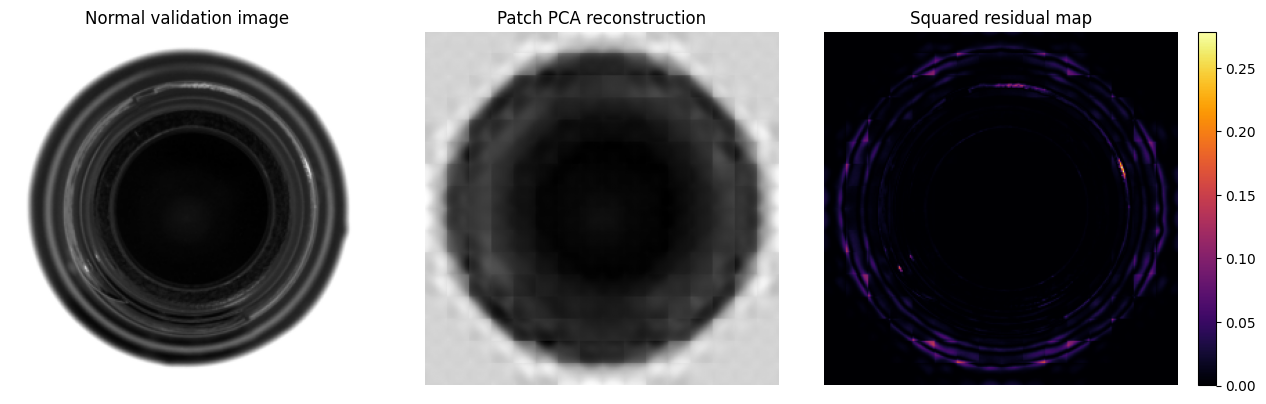

In [23]:
sample = val_ds[0]
x = sample['image'].unsqueeze(0).cpu().numpy()
original = x[0, 0]
reconstruction = patch_model.reconstruct(x)[0, 0]
anomaly = patch_model.anomaly_map(x)[0]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(original, cmap='gray'); axes[0].set_title('Normal validation image')
axes[1].imshow(reconstruction, cmap='gray'); axes[1].set_title('Patch PCA reconstruction')
im = axes[2].imshow(anomaly, cmap='inferno'); axes[2].set_title('Squared residual map')
fig.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## 8. Evaluation metrics — threshold from validation, metrics on test only

Image AUROC, pixel AUROC, pixel AP and AUPRO are computed on the official test split. The image-level threshold is the 95th percentile of normal validation image scores (target 5% validation FPR). AUPRO is normalized to [0,1] and integrated up to 30% pixel FPR using connected components of each ground-truth defect mask.

In [24]:
def collect_patch_outputs(dataset, model):
    labels, image_scores, masks, maps = [], [], [], []
    for index in range(len(dataset)):
        item = dataset[index]
        image = item['image'].unsqueeze(0).cpu().numpy()
        amap = model.anomaly_map(image)[0]
        mask = item['mask'].squeeze(0).cpu().numpy().astype(bool)
        labels.append(int(item['label']))
        image_scores.append(float(amap.max()))
        maps.append(amap.astype(np.float32))
        masks.append(mask)
    return (np.asarray(labels, dtype=np.uint8),
            np.asarray(image_scores, dtype=np.float64),
            np.stack(masks), np.stack(maps))


def compute_aupro(masks, anomaly_maps, max_fpr=0.30, n_thresholds=256):
    """Normalized AUPRO up to max_fpr; returns a value in [0,1].

    PRO is mean per-connected-defect-region overlap. FPR is the fraction of
    all normal pixels marked anomalous. The x-axis is explicitly clipped to
    [0,max_fpr] before integration, and duplicate FPR coordinates are
    collapsed by keeping the greatest PRO reached at that FPR.
    """
    masks = np.asarray(masks, dtype=bool)
    scores = np.asarray(anomaly_maps, dtype=np.float64)
    if masks.shape != scores.shape or masks.ndim != 3:
        raise ValueError(f'Expected matching (N,H,W) masks/maps; got {masks.shape} and {scores.shape}.')
    if not np.isfinite(scores).all():
        raise ValueError('Anomaly maps contain NaN or Inf.')
    if not 0.0 < max_fpr <= 1.0:
        raise ValueError('max_fpr must be in (0,1].')

    negative_count = int((~masks).sum())
    regions = []
    for mask in masks:
        labels, count = connected_components(mask)
        for region_id in range(1, count + 1):
            region = (labels == region_id)
            if region.any():
                regions.append(region)
    if not regions or negative_count == 0:
        return float('nan')

    # Include all score quantiles plus the extrema. Descending threshold
    # sweeps from very few predicted positives toward more predicted positives.
    thresholds = np.unique(np.quantile(scores, np.linspace(0.0, 1.0, n_thresholds)))
    thresholds = np.concatenate(([np.nextafter(scores.max(), np.inf)], thresholds[::-1]))
    points = [(0.0, 0.0)]
    for threshold in thresholds:
        predicted = scores >= threshold
        fpr = float(np.logical_and(predicted, ~masks).sum() / negative_count)
        pro = float(np.mean([
            np.logical_and(predicted, region).sum() / int(region.sum())
            for region in regions
        ]))
        if fpr <= max_fpr:
            points.append((max(0.0, fpr), min(1.0, max(0.0, pro))))
        else:
            # Thresholds are descending, so FPR cannot decrease afterwards.
            break

    points.sort(key=lambda pair: pair[0])
    xs = np.asarray([p[0] for p in points], dtype=np.float64)
    ys = np.asarray([p[1] for p in points], dtype=np.float64)
    unique_x = np.unique(xs)
    unique_y = np.asarray([ys[xs == x].max() for x in unique_x])

    # Integrate only within the requested FPR interval.
    inside = unique_x < max_fpr
    x_clip = unique_x[inside]
    y_clip = unique_y[inside]
    if len(x_clip) == 0 or x_clip[0] != 0.0:
        x_clip = np.insert(x_clip, 0, 0.0)
        y_clip = np.insert(y_clip, 0, 0.0)
    endpoint = float(np.interp(max_fpr, unique_x, unique_y)) if unique_x[-1] >= max_fpr else float(unique_y[-1])
    x_clip = np.append(x_clip, max_fpr)
    y_clip = np.append(y_clip, endpoint)

    area = float(np.trapezoid(y_clip, x_clip))
    normalized = area / max_fpr
    # PRO and FPR are both bounded by construction, so this is a strict
    # numerical sanity check rather than a metric-rescaling workaround.
    if not np.isfinite(normalized) or normalized < -1e-9 or normalized > 1.0 + 1e-9:
        raise RuntimeError(
            f'AUPRO calculation invalid: normalized={normalized}, '
            f'area={area}, max_fpr={max_fpr}, x_range=({x_clip.min()}, {x_clip.max()}), '
            f'PRO_range=({y_clip.min()}, {y_clip.max()}).'
        )
    return float(np.clip(normalized, 0.0, 1.0))


# 1) Calibrate threshold using normal validation images only.
val_labels, val_scores, _, _ = collect_patch_outputs(val_ds, patch_model)
if np.any(val_labels != 0):
    raise RuntimeError('Validation split must contain only good images.')
image_threshold = float(np.quantile(val_scores, 1.0 - VALIDATION_FPR, method='higher'))

# 2) Evaluate the official test split. Do not tune using these results.
test_labels, test_scores, test_masks, test_maps = collect_patch_outputs(test_ds, patch_model)
if np.unique(test_labels).size != 2:
    raise RuntimeError('Test split must contain both good and anomalous images.')

test_predictions = (test_scores >= image_threshold).astype(np.uint8)
flat_masks = test_masks.ravel().astype(np.uint8)
flat_scores = test_maps.ravel()

metrics = {
    'category': CATEGORY,
    'detector': 'Patch-wise PCA',
    'patch_size': PATCH_SIZE,
    'stride': STRIDE,
    'components': len(patch_model.components_),
    'retained_variance': float(patch_model.explained_variance_ratio_.sum()),
    'train_patches_used': patch_model.n_patches_used_,
    'validation_images': len(val_scores),
    'test_images': len(test_labels),
    'test_anomalous_images': int(test_labels.sum()),
    'image_threshold_from_val_good_5pct_fpr': image_threshold,
    'image_auroc': float(roc_auc_score(test_labels, test_scores)),
    'pixel_auroc': float(roc_auc_score(flat_masks, flat_scores)),
    'pixel_ap': float(average_precision_score(flat_masks, flat_scores)),
    'aupro_30pct_fpr': compute_aupro(test_masks, test_maps, max_fpr=AUPRO_MAX_FPR),
    'image_precision_at_val_threshold': float(precision_score(test_labels, test_predictions, zero_division=0)),
    'image_recall_at_val_threshold': float(recall_score(test_labels, test_predictions, zero_division=0)),
    'image_f1_at_val_threshold': float(f1_score(test_labels, test_predictions, zero_division=0)),
}
metrics_df = pd.DataFrame([metrics])
display(metrics_df.round(4))
assert 0.0 <= metrics['aupro_30pct_fpr'] <= 1.0

,category,detector,patch_size,stride,components,retained_variance,train_patches_used,validation_images,test_images,test_anomalous_images,image_threshold_from_val_good_5pct_fpr,image_auroc,pixel_auroc,pixel_ap,aupro_30pct_fpr,image_precision_at_val_threshold,image_recall_at_val_threshold,image_f1_at_val_threshold
0,bottle,Patch-wise PCA,32,16,8,0.9534,10000,21,83,63,0.311,0.827,0.4426,0.0557,0.965,0.9714,0.5397,0.6939


## 9. Save model and metrics

Outputs are written outside the raw MVTec dataset. This notebook does not modify original images or masks.

In [25]:
output_dir = Path('experiments/pca')
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / f'{CATEGORY}_patch_pca_claude.npz'
patch_model.save(model_path)

results_dir = Path('results/tables')
results_dir.mkdir(parents=True, exist_ok=True)
metrics_path = results_dir / f'{CATEGORY}_patch_pca_metrics.csv'
metrics_df.to_csv(metrics_path, index=False)

print('Saved model:', model_path)
print('Saved metrics:', metrics_path)

Saved model: experiments/pca/bottle_patch_pca_claude.npz
Saved metrics: results/tables/bottle_patch_pca_metrics.csv


## 10. How to interpret this run

- Compare this result with the earlier Global PCA bottle result, but note the score maps differ: this Patch PCA implementation uses squared residuals folded at pixel level.
- Pixel AP is especially informative when defective pixels are rare.
- AUPRO must be in [0,1]; the notebook asserts this to catch calculation errors.
- This is one category and one baseline configuration, not a final dataset-wide conclusion.
- If performance is weak, tune patch size, stride, retained variance, patch-mean removal and map mode using validation only; do not choose settings based on test metrics.
